# FXA solubility + LogD multi-readout preprocessing

Same pipeline as `fxa_multireadout.ipynb`, for `LogD (pH 7.40)` and solubility. Solubility is
**converted to `logS (mol/L)` before anything else**: the raw `Solubility (pH 7.40) (uM)` column
spans 0 to 2,530,000 uM (skew 11.4), so under `MSELoss` the top 1% of compounds would carry 88% of
the total squared error - and since val MSE also drives early stopping, checkpointing and the
Optuna objective, both training and model selection would be steered by ~10 compounds.

`log10` of the value in mol/L gives skew 0.06 / kurtosis -0.57, and puts the target on the same
scale the AqSolDB / ESOL literature reports (`logS`, range -7.00 to +0.40 here).

Note this is **not** the AqSolDB endpoint: that is intrinsic solubility of the neutral species in
pure water, this is buffered pH 7.4 solubility of ionizable compounds. Same units, different
measurement - do not pool the datasets or compare RMSE against an AqSolDB benchmark.

In [ ]:
import os
from glob import glob
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import ks_2samp

from mol_faith.data.create_dataset.create_multi_readout_data_splits import (
    create_n_multi_readout_splits,
)
from mol_faith.data.data_managers.smiles_data_manager import SMILESTokenizer
from mol_faith.data.data_managers.tokenization_helper import test_round_trip_fidelity
from mol_faith.data.preprocessing.clean_data import clean_molecular_data
from mol_faith.data.preprocessing.filter_data import filter_molecular_data


In [3]:
SOURCE_DATA_PATH = Path("../../../data/real_world/FXa_logs_logd_stratified/data_aggregated.csv")

SMILES_COLUMN = "SMILES"
LOGD_COLUMN = "LogD (pH 7.40)"
SOLUBILITY_COLUMN = "Solubility (pH 7.40) (uM)"

# Solubility is modelled as log10 of the concentration in mol/L, not as raw uM (see intro).
LOGS_COLUMN = "logS (mol/L)"

# The readouts that are stratified on jointly, and that each get their own split directory.
READOUT_COLUMNS = [LOGD_COLUMN, LOGS_COLUMN]

# Everything the pipeline produces lands here, mirroring the MolFaith `data/` layout.
DATA_DIR = Path("../../../data/real_world/FXa_logs_logd_stratified")

RAW_DIR = DATA_DIR / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

CLEANED_DIR = DATA_DIR / "cleaned"
CLEANED_DIR.mkdir(parents=True, exist_ok=True)

FILTERED_DIR = DATA_DIR / "cleaned_and_filtered"
FILTERED_DIR.mkdir(parents=True, exist_ok=True)

RAW_DATA_PATH = RAW_DIR / "raw_data.csv"
CLEANED_DATA_PATH = CLEANED_DIR / "cleaned_data.csv"
FILTERED_DATA_PATH = FILTERED_DIR / "filtered_data.csv"
VOCAB_PATH = FILTERED_DIR / "tokenizer_vocab.txt"

assert SOURCE_DATA_PATH.exists(), SOURCE_DATA_PATH

## Step 0 - Reduce to SMILES + the two readouts, and convert solubility to logS

Two decisions about the solubility column are made here, deliberately:

**Below-LOQ rows are dropped.** Three compounds (`CPD_46`, `CPD_461`, `CPD_948`) are recorded as
`0.0` uM. The smallest non-zero value in the column is exactly `0.1` uM and 78 compounds sit
between 0.1 and 0.9, so 0.1 uM is the assay reporting floor and these three are left-censored, not
true zeros. `log10(0)` is undefined, so they cannot be kept as-is.

**Ceiling values are kept.** The five largest values are the only entries in the whole column with
3 significant digits (the other 1010 have 1 or 2), and three of them work out to almost exactly
1 g/mL once converted with the molecular weight (1001.7, 1000.7, 997.9 g/L for MW 466, 396, 504).
1000 g/L is not a measurement for a 400-500 Da organic solid, it is a limit - these are very
likely "soluble at the highest concentration tested", back-converted to uM. They are kept anyway,
so the model fits that bound; if that turns out to be wrong, this is the cell to change.

In [ ]:
source_df = pd.read_csv(SOURCE_DATA_PATH)[[SMILES_COLUMN, LOGD_COLUMN, SOLUBILITY_COLUMN]]
print(f"{len(source_df)} rows in the source file")
source_df.head()

In [ ]:
below_loq = source_df[SOLUBILITY_COLUMN] <= 0
print(f"dropping {below_loq.sum()} rows at or below the assay LOQ (0.0 uM)")

raw_df = source_df[~below_loq].copy()
raw_df[LOGS_COLUMN] = np.log10(raw_df[SOLUBILITY_COLUMN] * 1e-6)
raw_df = raw_df[[SMILES_COLUMN, *READOUT_COLUMNS]].dropna().reset_index(drop=True)

print(f"{len(source_df)} -> {len(raw_df)} rows after dropping below-LOQ and missing values")
display(raw_df[READOUT_COLUMNS].describe())
display(raw_df[READOUT_COLUMNS].skew().rename("skew"))
raw_df.head()

In [ ]:
# SMILES must stay the first column: GraphDataManager reads it positionally.
raw_df.to_csv(RAW_DATA_PATH, index=False)
print(f"written to: {RAW_DATA_PATH}")
print(f"columns: {raw_df.columns.tolist()}")

## Step 1 - Cleaning

Writes `cleaned_data.csv`, `cleaning_summary.csv` and - if anything fails - `failed_cleaning.csv` /
`duplicates.csv` into `CLEANED_DIR`.

Note: duplicate canonical SMILES are dropped **entirely** (no representative is kept). Expect
1012 -> 997 molecules here, from 7 duplicate groups covering 15 rows.

In [ ]:
clean_molecular_data(
    dataset_path=str(RAW_DATA_PATH),
    output_path=str(CLEANED_DIR),
)

In [ ]:
for report in ("cleaning_summary.csv", "failed_cleaning.csv", "duplicates.csv"):
    path = CLEANED_DIR / report
    if path.exists():
        print(f"\n{report}:")
        display(pd.read_csv(path).head())

cleaned_df = pd.read_csv(CLEANED_DATA_PATH)
print(f"\n{len(cleaned_df)} molecules after cleaning, columns {cleaned_df.columns.tolist()}")

## Step 2 - Filtering

Same cutoffs as the other FXA datasets. FXA maxes out at 90 tokens / 49 heavy atoms, so nothing is
expected to be rejected - the step is kept so this dataset goes through the identical pipeline.

In [ ]:
MAX_SEQUENCE_LENGTH = 100  # same cutoffs as the original MolFaith dataset
MAX_HEAVY_ATOMS = 50

filter_molecular_data(
    input_data_path=str(CLEANED_DATA_PATH),
    output_dir=str(FILTERED_DIR),
    max_sequence_length=MAX_SEQUENCE_LENGTH,
    max_heavy_atoms=MAX_HEAVY_ATOMS,
)

## Step 3 - Check tokenizer

In [ ]:
tokenizer = SMILESTokenizer()
clean_and_filtered_data = pd.read_csv(FILTERED_DATA_PATH)
tokenizer.build_vocab_from_corpus(clean_and_filtered_data['SMILES'].tolist())
test_round_trip_fidelity(tokenizer, clean_and_filtered_data['SMILES'].tolist(), max_length=100)

In [ ]:
tokenizer.save_vocab(VOCAB_PATH)

## Step 4 - Create data splits

**`n_bins_per_readout=3`, not the module default of 4.** LogD and logS correlate **-0.736** here,
which makes the joint quantile grid diagonal-heavy: at 4 bins per readout the (lowest LogD
quartile, least soluble quartile) cell holds only 2 molecules, and the 70/20/10 split fails for
every seed because a 1-member stratum cannot be split into val and test. That is a property of the
data, not of the splitter - `fxa_multireadout.ipynb` gets away with 4 bins because pKi and LogD are
essentially independent there (correlation 0.041, smallest joint cell 34).

At 3 bins the grid is well filled (smallest cell 11) and no molecule has to be reassigned, so every
stratum stays a genuine LogD x solubility cell. Coarsening was preferred over reassigning the thin
cells' molecules to neighbouring strata, which was measured to place 29 molecules up to a full
stratum width outside the range of the stratum they were put in, for no measurable gain in how well
the splits actually balance.

`min_joint_cell_count=10` because the default of 20 asks for >=2 molecules of every stratum to reach
the 10% test set; at 11 the thinnest stratum contributes 1. The hard feasibility floor is 7 (a
stratum needs >=2 members in the 30% held-out set for the second split stage).

In [ ]:
# create_n_multi_readout_splits(
#     data_path=str(FILTERED_DATA_PATH),
#     base_output_path=str(DATA_DIR),
#     num_splits=5,
#     readout_column_names=READOUT_COLUMNS,
#     n_bins_per_readout=3,
#     min_joint_cell_count=10,
#     output_folder_names={LOGD_COLUMN: 'logd_data_splits', LOGS_COLUMN: 'logs_data_splits'},
# )

## Step 5 - Check the splits

In [4]:
def plot_splits(base_output_path, target_column_index, xlabel='Target Value'):
    split_folders = sorted(glob(os.path.join(base_output_path, 'data_split_*')))

    num_splits = len(split_folders)

    fig, axes = plt.subplots(nrows=num_splits, ncols=1, figsize=(10, 4 * num_splits))
    for i, split_folder in enumerate(split_folders):
        train_path = os.path.join(split_folder, 'train.csv')
        val_path = os.path.join(split_folder, 'val.csv')
        test_path = os.path.join(split_folder, 'test.csv')

        train_df = pd.read_csv(train_path)
        val_df = pd.read_csv(val_path)
        test_df = pd.read_csv(test_path)

        train_values = train_df.iloc[:, target_column_index]
        val_values = val_df.iloc[:, target_column_index]
        test_values = test_df.iloc[:, target_column_index]

        ax = axes[i] if num_splits > 1 else axes
        sns.kdeplot(train_values, color='blue', linewidth=2, label='Train', ax=ax)
        sns.kdeplot(val_values, color='orange', linewidth=2, linestyle='dashed', label='Validation', ax=ax)
        sns.kdeplot(test_values, color='red', linewidth=2, linestyle='dotted', label='Test', ax=ax)

        ax.set_title(f'Split {i+1}')
        ax.set_xlabel(xlabel)
        ax.set_ylabel('Density')
        ax.legend()

    plt.tight_layout()
    plt.show()

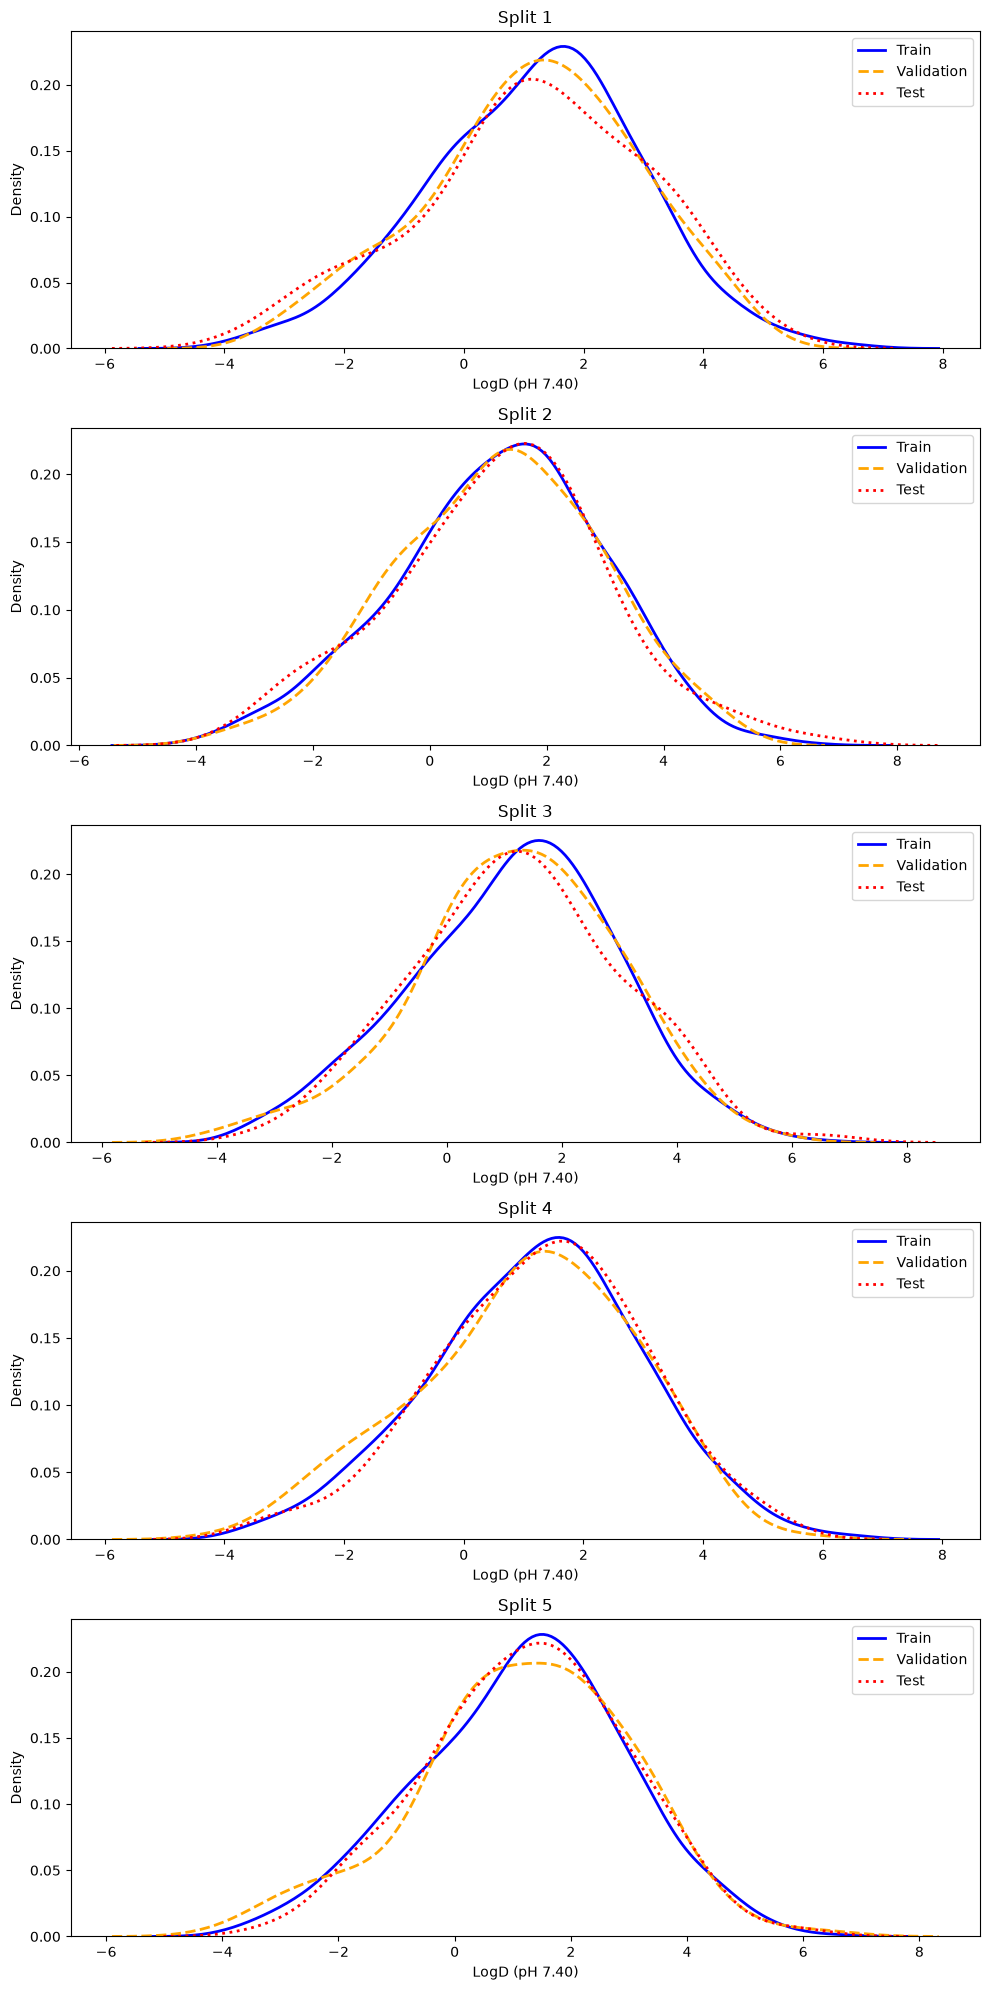

In [5]:
plot_splits(str(DATA_DIR / 'logd_data_splits'), 1, xlabel=LOGD_COLUMN)

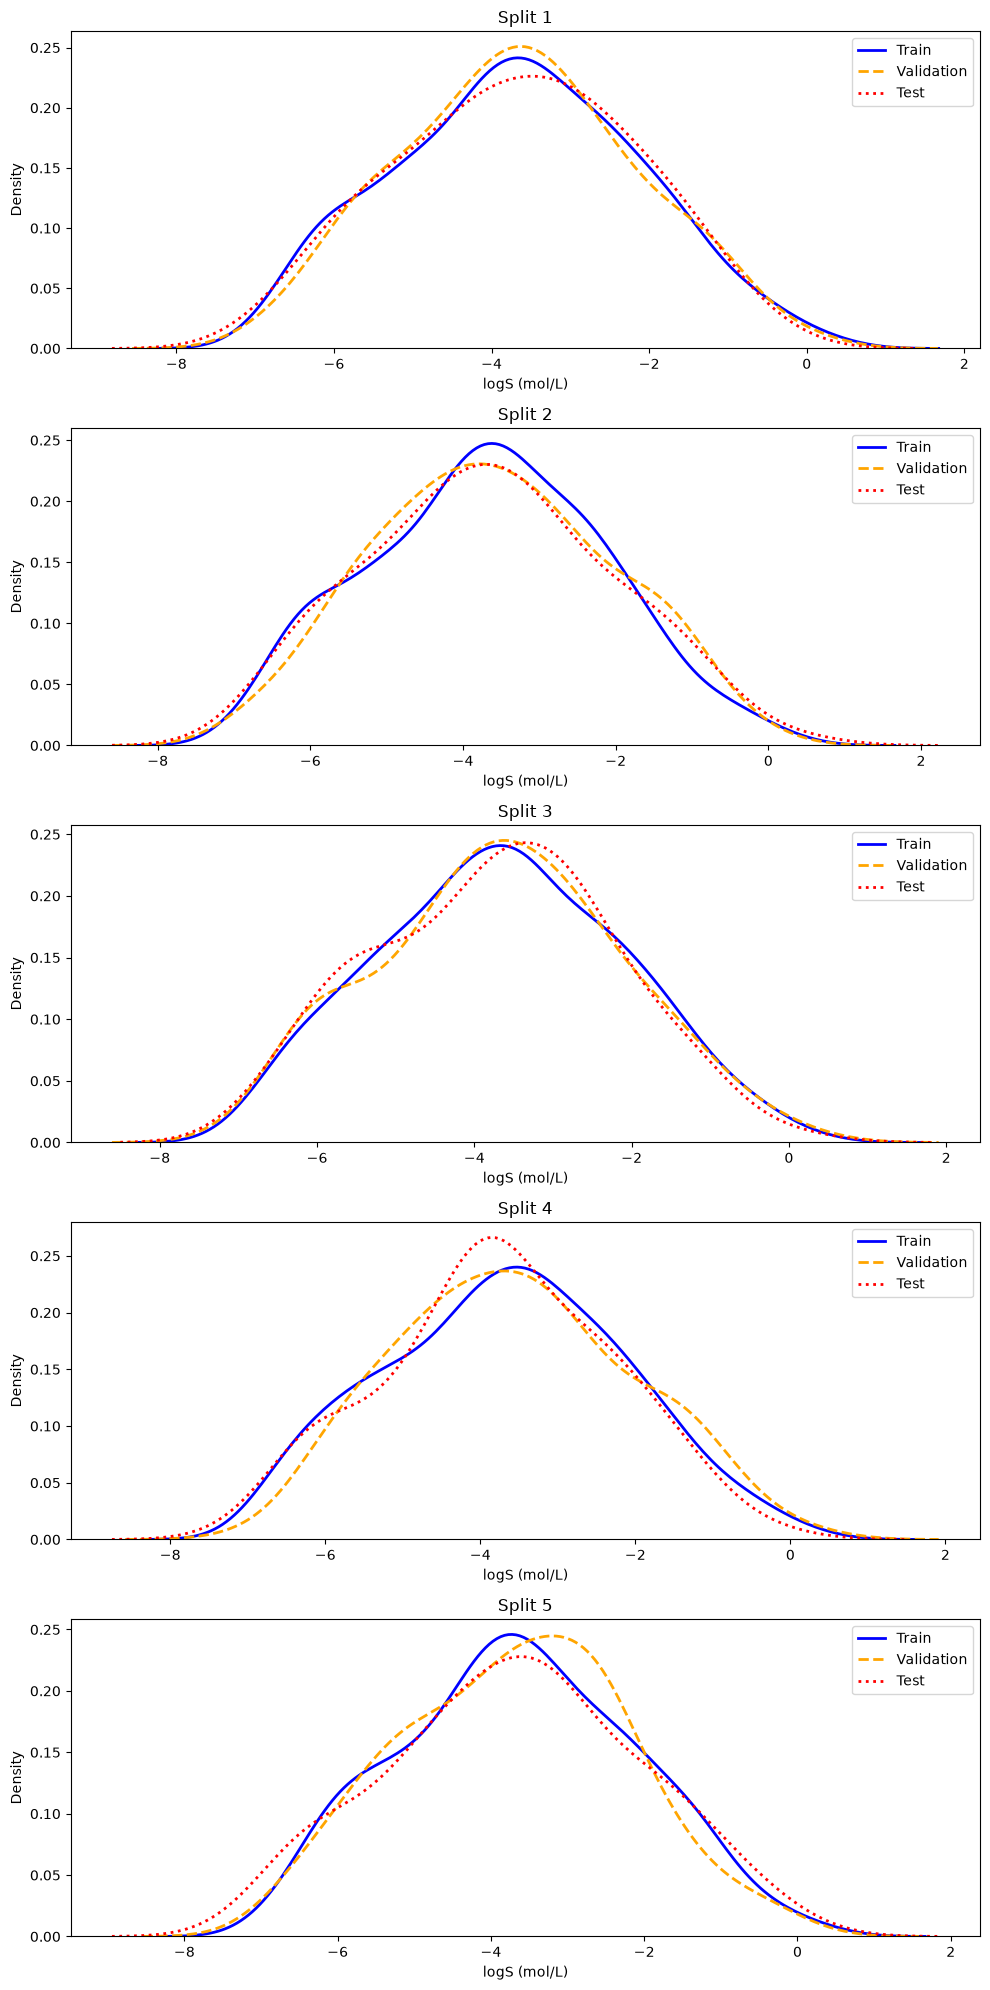

In [6]:
plot_splits(str(DATA_DIR / 'logs_data_splits'), 1, xlabel=LOGS_COLUMN)

### Numerical version of the same check

The two readout directories must describe the *same* molecules in the *same* order - single-target
models trained from either directory have to see identical splits. The KS tests are the numerical
form of the KDE plots above: train vs val and train vs test should not be distinguishable.

In [ ]:
for split_index in range(5):
    row = [f"split {split_index}"]

    frames = {}
    for folder, readout in (('logd_data_splits', LOGD_COLUMN), ('logs_data_splits', LOGS_COLUMN)):
        frames[readout] = {
            category: pd.read_csv(DATA_DIR / folder / f'data_split_{split_index}' / f'{category}.csv')
            for category in ('train', 'val', 'test')
        }

    for category in ('train', 'val', 'test'):
        left = frames[LOGD_COLUMN][category]['SMILES']
        right = frames[LOGS_COLUMN][category]['SMILES']
        assert left.equals(right), f"{category} SMILES differ between readout directories"

    all_smiles = pd.concat([frames[LOGD_COLUMN][c]['SMILES'] for c in ('train', 'val', 'test')])
    assert not all_smiles.duplicated().any(), "a molecule appears in more than one of train/val/test"

    sizes = [len(frames[LOGD_COLUMN][c]) for c in ('train', 'val', 'test')]
    row.append(f"{sizes[0]}/{sizes[1]}/{sizes[2]}")

    for readout in READOUT_COLUMNS:
        train = frames[readout]['train']['Target']
        val = frames[readout]['val']['Target']
        test = frames[readout]['test']['Target']
        row.append(f"{readout}: range {train.min():.2f}..{train.max():.2f} "
                   f"KS p(tr,val)={ks_2samp(train, val).pvalue:.2f} "
                   f"p(tr,test)={ks_2samp(train, test).pvalue:.2f}")

    print("  ".join(row))

print("\nSMILES identical across readout directories, no molecule in two categories.")